# 9 · BM25

**Owner:** Member 3 · **Branch:** `dev-bm25` · **Code:** `src/discovery/rank/bm25.py` → class `BM25Ranker` · **Writes to:** `eval/results/bm25.json`

**What it means:** BM25 adds up, for each query word, how rare the word is (IDF) times a **saturating** term frequency: the 1st occurrence counts a lot, the 10th barely more. It also scales term frequency by README length, so a long README needs more occurrences for the same score.

**Key idea:** Those two corrections are why BM25 usually beats TF-IDF (hypothesis H1): `k1` controls how fast repeated words stop counting, `b` how much README length is corrected for. It is our default method.

Full guide with starter code, and the Results sheet: [team plan](https://claude.ai/artifact/Rst8GHxAbeHavg4JS2RZV3) (tab 9 BM25). Handoff and setup: `docs/handoff-methods.md`.

### Settings to try
| Setting | Values | Why |
|---|---|---|
| k1 | 0.9, 1.2, 1.5, 2.0 | Saturation: small k1 = repeating a word barely helps. |
| b | 0.3, 0.5, 0.75, 0.9 | Length correction: 0 = none, 1 = full. |

**Fixed:** idf = log((N − n + 0.5) / (n + 0.5) + 1), never negative; our own implementation, checked against rank-bm25

### What we agreed (same for all five)
- **One tokenizer:** `tokenize()` from `discovery.preprocess.text`, for documents *and* queries. Never a private one.
- **One interface:** your class extends `SearchMethod` (`src/discovery/rank/base.py`): `fit(corpus)` → self, `search(query, k)` → `[{"doc_id": full_name, "score": float}]`, best first. `check_hits()` checks it.
- **Tune on the 5 development queries only** (`DEV`, replaced by the real ones in Phase 13). The 20 test queries are for the final number only.
- **Seed 42**, paths from `PATHS`, and don't edit the shared files (`rank/base.py`, `rank/devkit.py`, `preprocess/text.py`, `config/config.yaml`) on your branch: ask Member 6.
- Commit this notebook **with its outputs** on `dev-bm25`. No data files in git.

## 1. Setup: load the corpus and the shared tokenizer

**Check:** it prints 8,223 repositories, and `node.js` and `c#` come out of `tokenize()` in one piece.

In [1]:
%load_ext autoreload
%autoreload 2

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from discovery.config import PATHS, SEED, set_seed
from discovery.preprocess.text import doc_text, tokenize      # the ONE shared tokenizer (Phase 6)
from discovery.rank.base import check_hits
from discovery.rank.devkit import DEV, load_corpus, measure, save_results, show_top
from discovery.rank.bm25 import BM25Ranker

set_seed()
corpus = load_corpus()                                   # data/processed/corpus.parquet
ids = corpus["full_name"].tolist()                       # doc_id = full_name, "owner/name"
text = doc_text(corpus).tolist()                         # name + description + topics + README
print(f"{len(corpus):,} repositories |", tokenize("Built with Node.js and C#"))
print("development queries:", *DEV, sep="\n  ")

8,223 repositories | ['built', 'node.js', 'c#']
development queries:
  beginner inventory management system nestjs postgresql
  point of sale app with react
  school management system laravel
  hotel booking system spring boot
  simple chat application flutter firebase


## 2. Build: BM25

Everything BM25 needs is counted once: document lengths, the average length, document frequency per word, and posting lists with term frequencies.

**Check:** it runs once on the whole corpus without errors. Write down how long it took: it goes in the sheet.

<details><summary>Starter code from the team plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
import numpy as np
from collections import Counter, defaultdict

docs = [tokenize(t) for t in text]
N = len(docs)
dl = np.array([len(d) for d in docs]); avgdl = dl.mean()
tfs = [Counter(d) for d in docs]
df = Counter(w for c in tfs for w in c)
idf = {w: np.log((N - n + 0.5) / (n + 0.5) + 1) for w, n in df.items()}
inv = defaultdict(list)                              # term -> [(row, tf)]: a query only touches its own words
for i, c in enumerate(tfs):
    for w, f in c.items():
        inv[w].append((i, f))
print(f"N = {N:,} | average length {avgdl:.0f} tokens | idf('nestjs') = {idf.get('nestjs', 0):.2f}, idf('app') = {idf.get('app', 0):.2f}")
```
</details>

In [2]:
from collections import Counter, defaultdict

t = time.perf_counter()
docs = [tokenize(x) for x in text]                   # the shared tokenizer, once for the whole corpus
print(f"tokenized in {time.perf_counter() - t:.1f} s")

t = time.perf_counter()
N = len(docs)
dl = np.array([len(d) for d in docs]); avgdl = dl.mean()
tfs = [Counter(d) for d in docs]
df = Counter(w for c in tfs for w in c)
idf = {w: np.log((N - n + 0.5) / (n + 0.5) + 1) for w, n in df.items()}
inv = defaultdict(list)                              # term -> [(row, tf)]: a query only touches its own words
for i, c in enumerate(tfs):
    for w, f in c.items():
        inv[w].append((i, f))
print(f"counted in {time.perf_counter() - t:.1f} s")
print(f"N = {N:,} | {len(df):,} distinct words | average length {avgdl:.0f} tokens (median {np.median(dl):.0f})")
print(f"idf('nestjs') = {idf.get('nestjs', 0):.2f}, idf('inventory') = {idf.get('inventory', 0):.2f}, "
      f"idf('app') = {idf.get('app', 0):.2f}, idf('system') = {idf.get('system', 0):.2f}")

tokenized in 7.5 s


counted in 1.5 s
N = 8,223 | 148,623 distinct words | average length 692 tokens (median 361)
idf('nestjs') = 2.90, idf('inventory') = 2.02, idf('app') = 0.62, idf('system') = 0.55


## 3. Search: a free-text query in, a ranked list out

The formula, term by term. Only repositories that contain at least one query word get a score.

**Check:** the top 10 for `DEV[0]` look plausible when you read their names and descriptions.

<details><summary>Starter code from the team plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
def search(query, k=10, k1=1.5, b=0.75):
    s = np.zeros(N)
    for w in tokenize(query):
        for i, f in inv.get(w, ()):
            s[i] += idf[w] * f * (k1 + 1) / (f + k1 * (1 - b + b * dl[i] / avgdl))
    top = np.argsort(-s)[:k]
    return [{"doc_id": ids[i], "score": float(s[i])} for i in top if s[i] > 0]

search(DEV[0])
```
</details>

In [3]:
def search(query, k=10, k1=1.5, b=0.75):
    s = np.zeros(N)
    for w in tokenize(query):
        for i, f in inv.get(w, ()):
            s[i] += idf[w] * f * (k1 + 1) / (f + k1 * (1 - b + b * dl[i] / avgdl))
    top = np.argsort(-s, kind="stable")[:k]
    return [{"doc_id": ids[i], "score": float(s[i])} for i in top if s[i] > 0]

print(DEV[0])
pd.DataFrame(search(DEV[0])).merge(corpus[["full_name", "stars", "description"]], left_on="doc_id", right_on="full_name") \
  .drop(columns="full_name").assign(description=lambda d: d.description.str[:70]).round(2)

beginner inventory management system nestjs postgresql


,doc_id,score,stars,description
0,aminesaadGU/aqua-log,17.25,5,not specified
1,fathiranugrahh/stockroom,16.68,6,Full-stack inventory management for small busi...
2,samisams1/Inventory-Management-React-Nest-Grap...,16.19,13,"Inventory Management System with React, TypeSc..."
3,hmangam78/bookstoremanager,15.70,6,A production-style bookstore POS and inventory...
4,jmw5598/inventory-management-system,15.25,15,"Inventory management system using Angular 9, N..."
5,invntio/easybooks,15.11,5,Under construction. An open-source inventory m...
6,DavidRiusB/ChilyAPI,14.68,5,This API handles operations related to an e-co...
7,BasantElsaey/FullStack_Using_Nodejs_RoadMap,14.54,103,"In this repository , you'll find FullStack roa..."
8,sarzali07/Inventory-Management,14.53,5,not specified
9,Bekon0700/interview-questions,13.45,5,interview-questions


## 4. Move it into `src/discovery/rank/bm25.py` as `BM25Ranker`

The stub is already there with the right signature. Fill in `fit` and `search` (and `params`), then load it here with `discovery.rank.bm25.BM25Ranker`: autoreload picks up your edits.

**Check:** `check_hits` passes below, and in a terminal `pytest tests/test_methods.py -k bm25` passes (it was skipped until now).

<details><summary>The search method, as in the plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
    def search(self, query, k=10):
        ...  # the function above, with self.k1, self.b
```
</details>

In [4]:
method = BM25Ranker().fit(corpus, docs=docs)      # docs: reuse the tokens from step 2 (fit tokenizes if not given)
check_hits(method.search(DEV[0], 10), k=10)

# the class gives exactly the notebook function's ranking and scores
for q in DEV:
    a, b_ = search(q), method.search(q)
    assert [h["doc_id"] for h in a] == [h["doc_id"] for h in b_], q
    assert np.allclose([h["score"] for h in a], [h["score"] for h in b_]), q
print("class == notebook function on all 5 development queries")
method.params()

class == notebook function on all 5 development queries


{'k1': 1.5, 'b': 0.75}

## 5. Compare against a reference BM25 (rank-bm25)

`rank_bm25.BM25Okapi` uses a slightly different idf (it can go negative for very common words and floors them), so scores differ a little; the top 10 should mostly agree.

**Check:** 8+ of 10 the same on each development query, and your hand calculation for one repository matches the code.

<details><summary>The check, as in the plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
from rank_bm25 import BM25Okapi

ref = BM25Okapi(docs, k1=1.5, b=0.75)
for q in DEV:
    ours = [h["doc_id"] for h in search(q)]
    r = ref.get_scores(tokenize(q))
    theirs = [ids[i] for i in np.argsort(-r)[:10]]
    print(f"{len(set(ours) & set(theirs)):2d}/10 the same | {q}")

# one repository by hand: the score from the formula on paper = the score from the code
i = ids.index(search(DEV[0])[0]["doc_id"])
print({w: (tfs[i][w], round(idf.get(w, 0), 2)) for w in tokenize(DEV[0])}, "length", dl[i])
```
</details>

In [5]:
from rank_bm25 import BM25Okapi

ref = BM25Okapi(docs, k1=1.5, b=0.75)
for q in DEV:
    ours = [h["doc_id"] for h in method.search(q)]
    r = ref.get_scores(tokenize(q))
    theirs = [ids[i] for i in np.argsort(-r, kind="stable")[:10]]
    print(f"{len(set(ours) & set(theirs)):2d}/10 the same | {q}")

# Where they differ: rank-bm25's idf is log((N - n + 0.5) / (n + 0.5)), negative for words in more than half
# of the repositories; it replaces those with 0.25 x the average idf. Ours adds +1 inside the log instead.
common = [w for w in dict.fromkeys(tokenize(" ".join(DEV))) if df.get(w, 0) > N / 2]
print("\nwords in more than half of the repositories:", {w: (df[w], round(float(idf[w]), 2), round(float(ref.idf[w]), 2)) for w in common},
      "-> (repositories, our idf, rank-bm25 idf)")
ref.idf = dict(idf)                                   # give rank-bm25 our idf: the rest of the formula is the same
same = all([h["doc_id"] for h in method.search(q)] == [ids[i] for i in np.argsort(-ref.get_scores(tokenize(q)), kind="stable")[:10]]
           and np.allclose(sorted(ref.get_scores(tokenize(q)), reverse=True)[:10], [h["score"] for h in method.search(q)])
           for q in DEV)
print("with our idf, rank-bm25 gives exactly our top 10 and scores on all 5 queries:", same)

# one repository by hand: the formula on paper = the code
top = method.search(DEV[0], 1)[0]
i = ids.index(top["doc_id"])
print(f"\n{top['doc_id']}: length {dl[i]} tokens, avgdl {avgdl:.1f}, k1 = 1.5, b = 0.75")
norm = 1.5 * (1 - 0.75 + 0.75 * dl[i] / avgdl)
print(f"length part: k1 * (1 - b + b * |d| / avgdl) = 1.5 * (0.25 + 0.75 * {dl[i]} / {avgdl:.1f}) = {norm:.3f}")
hand = 0.0
for w in tokenize(DEV[0]):
    f, w_idf = tfs[i][w], idf.get(w, 0)
    part = w_idf * f * 2.5 / (f + norm) if f else 0.0
    hand += part
    print(f"  {w:12s} tf {f}  idf {w_idf:.3f}  ->  {w_idf:.3f} * {f} * 2.5 / ({f} + {norm:.3f}) = {part:.3f}")
print(f"by hand {hand:.3f} | code {top['score']:.3f}")
assert abs(hand - top["score"]) < 1e-6
method.explain(DEV[0], top["doc_id"])

10/10 the same | beginner inventory management system nestjs postgresql
 6/10 the same | point of sale app with react
 8/10 the same | school management system laravel
10/10 the same | hotel booking system spring boot
 8/10 the same | simple chat application flutter firebase

words in more than half of the repositories: {'system': (4768, 0.55, 2.0), 'app': (4445, 0.62, 2.0), 'application': (4595, 0.58, 2.0)} -> (repositories, our idf, rank-bm25 idf)
with our idf, rank-bm25 gives exactly our top 10 and scores on all 5 queries: True

aminesaadGU/aqua-log: length 110 tokens, avgdl 692.2, k1 = 1.5, b = 0.75
length part: k1 * (1 - b + b * |d| / avgdl) = 1.5 * (0.25 + 0.75 * 110 / 692.2) = 0.554
  beginner     tf 1  idf 2.764  ->  2.764 * 1 * 2.5 / (1 + 0.554) = 4.447
  inventory    tf 1  idf 2.018  ->  2.018 * 1 * 2.5 / (1 + 0.554) = 3.246
  management   tf 1  idf 0.720  ->  0.720 * 1 * 2.5 / (1 + 0.554) = 1.158
  system       tf 1  idf 0.545  ->  0.545 * 1 * 2.5 / (1 + 0.554) = 0.877
  nes

,word,tf,idf,score
0,beginner,1.0,2.764,4.447
1,inventory,1.0,2.018,3.246
2,management,1.0,0.720,1.158
3,system,1.0,0.545,0.877
4,nestjs,1.0,2.904,4.673
5,postgresql,1.0,1.771,2.849


## 6. Read your top 10 on the development queries

Read them. Write down two good results and two bad ones, and why each bad one ranked high (in the markdown cell under the output).

**Check:** you can say in one sentence why each bad result ranked high.

In [6]:
show_top(method, corpus, DEV)


# beginner inventory management system nestjs postgresql   (10 hits)
   17.251  aminesaadGU/aqua-log                         ★5      not specified
   16.680  fathiranugrahh/stockroom                     ★6      Full-stack inventory management for small businesses (UMKM).
   16.192  samisams1/Inventory-Management-React-Nest-Gr ★13     Inventory Management System with React, TypeScript, NestJS, 
   15.702  hmangam78/bookstoremanager                   ★6      A production-style bookstore POS and inventory system built 
   15.251  jmw5598/inventory-management-system          ★15     Inventory management system using Angular 9, Ngrx, NestJS, T
   15.107  invntio/easybooks                            ★5      Under construction. An open-source inventory management syst
   14.680  DavidRiusB/ChilyAPI                          ★5      This API handles operations related to an e-commerce platfor
   14.540  BasantElsaey/FullStack_Using_Nodejs_RoadMap  ★103    In this repository , you'll find FullS

**Two good results**
- `samisams1/Inventory-Management-React-Nest-GraphQL-Prisma` (#3) and `jmw5598/inventory-management-system` (#5): inventory management systems built with NestJS. The query words are in the name and the description, which is exactly what BM25 rewards.
- *hotel booking system spring boot*: the top 6 are all Spring Boot hotel booking backends, and *simple chat application flutter firebase* gives 10 Flutter chat apps, most on Firebase. When the query names a common kind of project and a framework, BM25 is hard to beat.

**Two bad results, and why they ranked high**
- `aminesaadGU/aqua-log` (#1 for the inventory query) is an aquarium tracker *"for beginner and expert aquarists"*. It is short (110 tokens against an average of 692, so the length correction lifts it) and contains every query word once, including *beginner*, whose idf (2.76) is nearly as high as *nestjs* (2.90). BM25 cannot tell *beginner* the audience from *beginner* the topic. The silver labels count it as relevant too: it was collected for the inventory | nestjs slice.
- `Bekon0700/interview-questions` (#10), `BasantElsaey/FullStack_Using_Nodejs_RoadMap` (#8), and `resumejob/free-project-course` (#9 for hotel, 5,382 stars): notes, roadmaps and course lists that *mention* every technology and the word *beginner* without *being* the project. These are the link lists the EDA flagged; Phases 11–12 (list filter, popularity) have to deal with them, BM25 alone cannot.

## 7. Tune on the 5 development queries only

Grid over k1 × b (16 combinations) on the 5 development queries, mean NDCG@10. Plot it as a heatmap: it is report material.

Until Phase 13 gives the development labels, compare settings by reading the top 10 (step 6). When `eval/qrels.csv` has the development labels, use `discovery.evaluation.metrics.ndcg_at_k` and keep the setting with the best mean NDCG@10. **Never tune on the 20 test queries.**

**Check:** a small table: each setting tried, what changed in the top 10 (later: mean NDCG@10). Keep the best and note it in the sheet.

{'beginner inventory management ': '42 x2, 670 x1', 'point of sale app with react': '80 x2, 358 x1', 'school management system larav': '84 x2, 250 x1', 'hotel booking system spring bo': '80 x2, 479 x1', 'simple chat application flutte': '82 x2, 667 x1'}


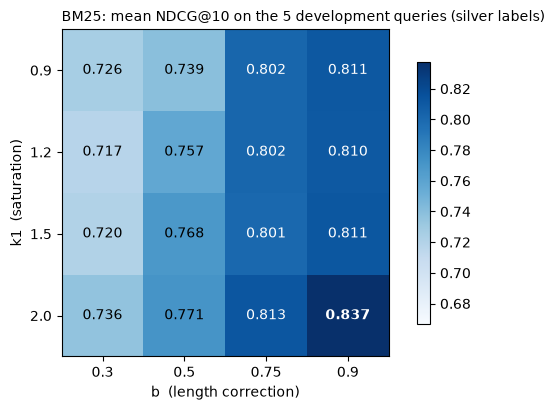

best: k1 = 2.0, b = 0.9  (0.837) | default k1 = 1.5, b = 0.75 (0.801)
spread over the grid: 0.717 to 0.837


,"1.5, 0.75","2.0, 0.9"
beginner inventory management system nes,0.749,0.799
point of sale app with react,0.550,0.525
school management system laravel,1.000,1.000
hotel booking system spring boot,0.797,0.927
simple chat application flutter firebase,0.907,0.937


In [7]:
# There are no labels yet (Phase 13), so this grid uses SILVER labels: a stand-in, not the final number.
# Each development query matches one collection slice (domain | framework) from Phase 2:
#   grade 2 = the repository was collected for that exact slice, grade 1 = same domain, other framework.
# Silver labels come from GitHub's own keyword search, so they favour word matching and miss relevant
# repositories outside the slice. Re-run this cell with the real development labels when they exist.
SLICE = dict(zip(DEV, [("inventory management", "nestjs"), ("point of sale", "react"), ("school management", "laravel"),
                       ("booking system", "spring-boot"), ("chat application", "flutter")]))

def silver(q):
    dom, fw = SLICE[q]
    g = {}
    for name, sel in zip(ids, corpus["selected_by"]):
        if f"{dom}|{fw}" in sel:
            g[name] = 2
        elif any(s.startswith(dom + "|") for s in sel):
            g[name] = 1
    return g

def ndcg10(ranked, grades):
    gain = [grades.get(d, 0) for d in ranked[:10]]
    dcg = sum((2**g - 1) / np.log2(r + 2) for r, g in enumerate(gain))
    ideal = sorted(grades.values(), reverse=True)[:10]
    return dcg / sum((2**g - 1) / np.log2(r + 2) for r, g in enumerate(ideal))

QRELS = {q: silver(q) for q in DEV}
print({q[:30]: f"{sum(v == 2 for v in g.values())} x2, {sum(v == 1 for v in g.values())} x1" for q, g in QRELS.items()})

K1, B = [0.9, 1.2, 1.5, 2.0], [0.3, 0.5, 0.75, 0.9]
grid = pd.DataFrame(index=pd.Index(K1, name="k1"), columns=pd.Index(B, name="b"), dtype=float)
per_q = {}
for k1 in K1:
    for b in B:
        m = method.with_params(k1=k1, b=b)
        per_q[(k1, b)] = [ndcg10([h["doc_id"] for h in m.search(q)], QRELS[q]) for q in DEV]
        grid.loc[k1, b] = np.mean(per_q[(k1, b)])

fig, ax = plt.subplots(figsize=(6, 4.2))
im = ax.imshow(grid.values, cmap="Blues", vmin=grid.values.min() - .05, vmax=grid.values.max())
ax.set_xticks(range(len(B)), B); ax.set_yticks(range(len(K1)), K1)
ax.set_xlabel("b  (length correction)"); ax.set_ylabel("k1  (saturation)")
best = np.unravel_index(np.argmax(grid.values), grid.shape)
for (r, c), v in np.ndenumerate(grid.values):
    ax.text(c, r, f"{v:.3f}", ha="center", va="center", fontsize=10,
            color="white" if v > grid.values.mean() else "black", fontweight="bold" if (r, c) == best else None)
ax.set_title("BM25: mean NDCG@10 on the 5 development queries (silver labels)", fontsize=10, loc="left")
fig.colorbar(im, ax=ax, shrink=.8); plt.tight_layout(); plt.show()

print(f"best: k1 = {K1[best[0]]}, b = {B[best[1]]}  ({grid.values.max():.3f}) | default k1 = 1.5, b = 0.75 ({grid.loc[1.5, 0.75]:.3f})")
print(f"spread over the grid: {grid.values.min():.3f} to {grid.values.max():.3f}")
pd.DataFrame({f"{k1}, {b}": v for (k1, b), v in per_q.items() if (k1, b) in [(1.5, 0.75), (K1[best[0]], B[best[1]])]},
             index=[q[:40] for q in DEV]).round(3)

**Tuning result (silver labels, 5 queries)**

- **b matters, k1 barely.** Down each column the score moves by 0.03 at most; across b it goes from 0.72 to 0.81–0.84. With b ≥ 0.75 the long READMEs (roadmaps, course lists) drop out: the top 10 average 930 tokens at b = 0.3 and 303 at b = 0.75 (next cell).
- **Best: k1 = 2.0, b = 0.9 (0.837)** against 0.801 for the default. The gain comes mostly from one query (hotel booking, 0.80 → 0.93) and *point of sale* gets slightly worse, on labels that are themselves noisy.
- **Decision:** keep the default **k1 = 1.5, b = 0.75** in `BM25Ranker` for now, and re-run this cell with the real development labels from Phase 13. Switch to 2.0 / 0.9 only if it still wins there. b below 0.75 is out either way.

## 8. Speed, results file, hand in

`measure()` times the build and the queries; `save_results()` writes `eval/results/bm25.json` in the format the Results sheet imports. The metrics stay empty until Phase 13–14: then Member 6's `evaluate_method(method, split="test")` fills them in and you import the file in the **Results sheet** tab of the team plan, add your observations and download the PDF.

**Check:** `eval/results/bm25.json` exists; this notebook is committed with its outputs on `dev-bm25`; `pytest` passes.

In [8]:
# what b does: the average length (tokens) of the top 10, low b vs high b
for b in [0.3, 0.75, 0.9]:
    m = method.with_params(b=b)
    lens = [np.mean([dl[ids.index(h["doc_id"])] for h in m.search(q)]) for q in DEV]
    print(f"b = {b:<4}: top-10 repositories are {np.mean(lens):5.0f} tokens long on average (corpus: {avgdl:.0f})")

speed = measure(lambda: BM25Ranker().fit(corpus), DEV)     # build includes tokenizing the corpus
print(speed)
print(save_results(method, speed))

b = 0.3 : top-10 repositories are   930 tokens long on average (corpus: 692)
b = 0.75: top-10 repositories are   303 tokens long on average (corpus: 692)
b = 0.9 : top-10 repositories are   254 tokens long on average (corpus: 692)


{'build_s': 8.45, 'query_ms_median': 0.46, 'index_mb': 24.4}
/Users/user/Documents/Y4/IR/open-source-discovery-engine/backend/eval/results/bm25.json


## Extra (optional): BM25F: score the fields separately

Give name and topics their own length normalisation and a weight (for example name × 3), then add the fields up. Compare with plain BM25 on the development queries.

In [9]:
# BM25F: each field gets its own length normalisation and a weight, then the weighted tf is saturated once.
# Fields: title = name + topics, description, README. Weights tried: title x3, description x2, README x1.
from scipy import sparse

name_topics = (corpus["name"].str.replace(r"[-_]", " ", regex=True) + " "
               + corpus["topics"].map(lambda t: " ".join(x.replace("-", " ") for x in t)))
desc = corpus["description"].where(corpus["description"] != "not specified", "")
fields = {"title": [tokenize(x) for x in name_topics], "desc": [tokenize(x) for x in desc],
          "readme": [tokenize(x) for x in corpus["readme"]]}
vocab = method.vocab

def tf_matrix(toks):
    r, c, v = [], [], []
    for i, d in enumerate(toks):
        for w, f in Counter(d).items():
            if w in vocab:
                r.append(i); c.append(vocab[w]); v.append(f)
    return sparse.csc_matrix((np.array(v, float), (r, c)), shape=(N, len(vocab)))

F = {f: (tf_matrix(t), np.array([len(d) for d in t], float)) for f, t in fields.items()}

def bm25f(query, weights, k=10, k1=1.5, b=0.75):
    wtf = sparse.csc_matrix((N, len(vocab)))
    for f, (m, L) in F.items():
        norm = 1 - b + b * L / max(L.mean(), 1e-9)
        wtf = wtf + sparse.diags(weights[f] / norm) @ m
    wtf = wtf.tocsc()
    s = np.zeros(N)
    for w in tokenize(query):
        j = vocab.get(w)
        if j is None:
            continue
        col = wtf[:, j].toarray().ravel()
        s += method.idf[j] * col * (k1 + 1) / (col + k1)
    top = np.argsort(-s, kind="stable")[:k]
    return [ids[i] for i in top if s[i] > 0]

rows = []
for wname, wts in {"plain BM25 (one field)": None, "BM25F title x3, desc x2": {"title": 3, "desc": 2, "readme": 1},
                   "BM25F title x5, desc x2": {"title": 5, "desc": 2, "readme": 1}}.items():
    ranked = {q: ([h["doc_id"] for h in method.search(q)] if wts is None else bm25f(q, wts)) for q in DEV}
    rows.append({"variant": wname, **{q[:28]: ndcg10(ranked[q], QRELS[q]) for q in DEV},
                 "mean": np.mean([ndcg10(ranked[q], QRELS[q]) for q in DEV])})
pd.DataFrame(rows).set_index("variant").round(3)

,beginner inventory managemen,point of sale app with react,school management system lar,hotel booking system spring,simple chat application flut,mean
variant,,,,,,
plain BM25 (one field),0.749,0.550,1.0,0.797,0.907,0.801
"BM25F title x3, desc x2",0.740,0.578,1.0,0.797,0.907,0.804
"BM25F title x5, desc x2",0.743,0.529,1.0,0.797,0.927,0.799


## What we found

- **Speed:** builds in about 8 s for 8,223 repositories (tokenizing is ~7 s of that, counting under 1 s), answers a query in 0.4 ms (median), index 24 MB. No GPU, nothing to download.
- **Correct:** the hand calculation for one repository matches the code (17.251). Given our idf, `rank_bm25.BM25Okapi` returns exactly our top 10 and scores on all 5 queries. Out of the box it agrees on 6–10 of 10: its idf goes negative for words in more than half of the repositories (*system*, *app*, *application*) and it floors them at 2.0, against ~0.6 for ours, so it over-rewards *app*. Ours never goes negative, as agreed.
- **Setting:** k1 = 1.5, b = 0.75 (default) kept for now; b is what matters, k1 hardly does. Best on silver labels: k1 = 2.0, b = 0.9 (0.837 vs 0.801), to confirm on the real labels.
- **Good:** precise when the query names the kind of project and a framework (hotel booking + Spring Boot, chat + Flutter: nearly all of the top 10 fit).
- **Bad:** (1) a short README that happens to contain every query word wins (*beginner* aquarium tracker for the inventory query); (2) roadmaps, interview notes and course lists that name every technology get in. Synonyms are missed entirely: a "stock tracker" never matches "inventory" (semantic search, 10.1).
- **BM25F** (name + topics ×3, description ×2, README ×1): 0.804 vs 0.801, no real gain, so plain BM25 over one field stays.
- `eval/results/bm25.json` is written (params + speed); the metrics fill in after Phase 14 (`evaluate_method`).